## **Praktikum Sistem Komunikasi Multimedia/Sistem dan Teknologi Multimedia**



---



* Nama: Dyelvio Wijaya
* NIM: 211344012
* Kelas: 3NK


## Modul 7: ELIAS GAMMA & ELIAS DELTA - BAGIAN DECODER

# Instruksi!

Sebelum melakukan pekerjaan di bawah, ada beberapa hal yang harus diperhatikan.

* Waktu pengerjaan sesuai dengan deadline pada GCR.
* GCR akan ditutup setelah jam tersebut.
* Waktu submit ke GCR berpengaruh pada nilai, lebih cepat akan mendapat nilai tambahan.
* Jika ada kendala saat upload file ipynb, maka bisa dengan menyematkan link google collabnya pada kolom submission tugas di GCR.
* Jika ada pertanyaan bisa diajukan di grup perkuliahan.

*selamat mengerjakan*

### Pendahuluan

**Elias Gamma Coding**

Metode ini dikembangkan oleh Peter Elias. Dengan teknik pengkodean:
1. Tulis dalam biner
2. Jumlah bit pada proses no.1 dikurang satu untuk menentukan jumlah nol (zeros) yang
harus ditambahkan di muka angka tersebut.
Contoh ada sebuat bilangan 11:
1. Langkah pertama adalah konversi 11 menjadi biner, yakni 1011.
2. Cari jumlah bit/pangkat tertinggi pada proses pertama, lalu kurangi 1.

Gunakan jumlah tersebut untuk menambahkan angka 0 didepan biner yang terdapat pada proses pertama.
Hasilnya adalah 0001011.

Sehingga jika didapatkan deretan angka 11, 15, dan 27 maka dengan elias gamma code deretan angka tersebut dapat diubah menjadi 00010110001111000011011.

Fungsi dari elias gamma code ini adalah pengguna dapat mengirim banyak angka berjajar sekaligus, sebab jika kita hanya mengubah bilangan tersebut menjadi biner maka akan sulit melakukan decode.

Sebagai contoh tiga bilangan yang terdapat pada contoh di atas. Jika data
tersebut dikirim 1011111111011 saja, maka akan ada banyak variasi kombinasi biner untuk mendapatkan nilai desimalnya.

Untuk bagian decoder proses yang harus dilakukan adalah :
1. Menghitung jumlah nol sebelum ditemukan bilangan 1.
2. Lalu jumlah nol tadi ditambahkan 1, maka angka hasil penjumlahan tersebut merupakan jumlah bit yang harus dikonversikan ke desimal.

Contoh pada biner 0001011. Langkah pertama adalah menghitung angka nol di awal, sehingga didapatkan nilai 3. Nilai 3 tersebut ditambahkan 1 menjadi 4, artinya 4 bit setelah deretan 0 harus dikonversikan menjadi desimal. Didapat biner 1001 atau jika dikonversikan ke dalam desimal menjadi 11.



---



**Elias Delta Coding & Decoding**

Seperti Elias Gamma, kode ini ditemukan oleh Peter Elias. Kode ini menerapkan juga metode
pada gamma coding, terutama di bagian kepala. Tekniknya adalah sebagai berikut:
1. Cari pangkat tertinggi binernya, misalnya desimal 11 jika dibinerkan menjadi 1011 dimana
pangkat tertingginya adalah 3. Jadi N’=3.
2. Gunakan Gamma Coding untuk mengkodekan bilangan N dimana N=N’+1. Jadi untuk
kasus desimal 11 maka kita harus membuat Gamma Coding dari 4 yaitu 00100.
3. Tambahkan sisa N’ binary pada hasil no.2. Jadi diperoleh jawaban 00100011.
Jika diberikan deretan angka 35, 101, dan 112, maka akan didapatkan output dengan metode Elias Delta Code sebagai berikut:

00110000110011110010100111110000

Berikutnya adalah melakukan decode menggunakan Elias Delta Coding, prinsipnya adalaH kebalikan dari langkah satu sampai tiga di atas. Misalnya kita akan mendekode 00100011.

1. Temukan jumlah zero sebelum ditemukan angka satu, yaitu 00 atau berjumlah 2 bit. Berarti ada (2+1) angka yang harus diperhatikan setelah dua angka nol ini, yaitu 100. DiMana angka 100 jika dikonversikan dalam desimalnya berarti 4, jadi kita mendapatkan N’ dengan N-1 atau 4-1 = 3.
2. Jika N’ telah diketahui (yaitu 3) maka ada 3 bit tersisa yang menjadi bagian bilangan itu yakni 011. Jadi diperoleh jawaban 1011 (ditambahkan digit 1 di depan biner sebelumnya) yang artinya 11.


---

### Langkah-langkah Percobaan

1. Buatlah program decoder dengan metode Elias Gamma Code untuk mengembalikan data yang dihasilkan pada praktikum sebelumnya.
2. Lakukan juga proses decoder pada hasil yang didapat dari encoder dengan metode Elias Delta Code sebelumnya.
3. Lampirkan flowchart, program dan screenshot hasil pada laporan yang dibuat.

**Instruksi:**





In [6]:
#tuliskan fungsi program pada tiap barisnya

def GammaDecode(input): #Pendeklarasian sebuah fungsi GammaDecode
 i = 0 #menginisialisasi variabel i(tipe data int) yang diisikan dengan nilai 0
 N = 1 #menginisialisasi variabel N(tipe data int) yang diisikan dengan nilai 1
 gammaResult = [] #menginisialisasi variabel gammaResult(tipe data array) yang diisikan dengan nilai kosong

 while i < len(input): #Perulangan sampai i telah melebihi banyaknya data dari input(jumlah bit dari input)
  if input[i] == "1": #Suatu pengkondisian disaat sedang proses scanning apabila bertemu dengan nilai 1 maka akan mengeksekusi program di dalam if
    gammaResult.append(int(input[i:i+N],2)) #memasukkan nilai array yang telah dilakukan konversi oleh fungsi dari int() dengan basis 2 yaitu biner ke desimal, dengan mengambil indeks awal i sampai i+N
    #print(gammaResult)
    i = i + N #Memasukkan nilai awal i jika telah terjadi proses decode, sehingga tidak mengulang dari awal atau memulai dari indeks i, namun dari indeks i + N
    N = 1 #Memasukkan nilai awal kembali dari N yaitu 1 setelah terjadi proses decode
  i = i + 1 #proses increment untuk i
  N = N + 1 #proses increment untuk N
 return gammaResult #Proses pengembalian nilai gammaResult untuk diberikan atau dimasukkan ke dalam sebuah varibel yang memanggil fungsi GammaDecode()

def DeltaDecode(input): #Pendeklarasian sebuah fungsi DeltaDecode
  i = 0 #menginisialisasi variabel i(tipe data int) yang diisikan dengan nilai 0
  N = 1 #menginisialisasi variabel N(tipe data int) yang diisikan dengan nilai 1
  deltaResult = [] #menginisialisasi variabel deltaResult(tipe data array) yang diisikan dengan nilai kosong

  while i < len(input): #Perulangan sampai i telah melebihi banyaknya data dari input(jumlah bit dari input)
    if input[i] == "1": #Suatu pengkondisian disaat sedang proses scanning apabila bertemu dengan nilai 1 maka akan mengeksekusi program di dalam if
      x = int(input[i:i+N],2)-1 #memasukkan nilai untuk x yang telah dilakukan konversi oleh fungsi dari int() dengan basis 2 yaitu biner ke desimal,
      #dengan mengambil indeks awal i sampai i+N, dan setelah proses konversi akan dikurangi dengan 1
      delta_bin = '1'+input[i+N:i+N+x] #memasukkan nilai untuk delta_bin dengan menjumlahkan terlebih dahulu data biner yang ada di index i+N dengan akhir indeks i+N+x kemudian dijumlahkan 1 di awal data biner(MSBnya)
      delta_dec = int(delta_bin, 2) #memasukkan nilai untuk delta_dec yang telah dilakukan konversi oleh fungsi dari int() dengan basis 2 yaitu biner ke desimal, dengan data yang dikonversi yaitu delta_bin
      i = i + N + x #Memasukkan nilai awal i jika telah terjadi proses decode, sehingga tidak mengulang dari awal atau memulai dari indeks i, namun dari indeks i + N + x
      N = 1 #Memasukkan nilai awal kembali dari N yaitu 1 setelah terjadi proses decode
      deltaResult.append(delta_dec)  #memasukkan nilai array ke deltaResult
    i = i + 1 #proses increment untuk i
    N = N + 1 #proses increment untuk N
  return deltaResult #Proses pengembalian nilai deltaResult untuk diberikan atau dimasukkan ke dalam sebuah varibel yang memanggil fungsi DeltaDecode

data_gamma = "00001011100000100011000001001000000010110000000101101" #inisialisasi data yang akan didecode untuk metode gamma, yang akan dimasukkan ke variabel data_gamma
data_delta = "0010101110011000011001100010000110011000011001101"  #inisialisasi data yang akan didecode untuk metode delta, yang akan dimasukkan ke variabel data_delta

Decoding_gamma = GammaDecode(data_gamma) #proses pemanggilan fungsi GammaDecode(dengan memasukkan input = data_gamma) dan hasil akhir nanti akan ditampung ke variabel Decoding_gamma
Decoding_delta = DeltaDecode(data_delta) #proses pemanggilan fungsi DeltaDecode(dengan memasukkan input = data_delta) dan hasil akhir nanti akan ditampung ke variabel Decoding_delta

print('input gamma: \n\t',data_gamma) #mencetak nilai data_gamma
print('gamma decoding: \n\t',Decoding_gamma) #mencetak nilai Decoding_gamma
print('input delta: \n\t',data_delta) #mencetak nilai data_delta
print('delta decoding: \n\t',Decoding_delta) #mencetak nilai Decoding_delta


input gamma: 
	 00001011100000100011000001001000000010110000000101101
gamma decoding: 
	 [23, 35, 36, 44, 45]
input delta: 
	 0010101110011000011001100010000110011000011001101
delta decoding: 
	 [23, 35, 36, 44, 45]




> Analisa dari program di atas:

Dalam program diatas terdapat dua buah fungsi yang dibuat yaitu fungsi GammaDecode() yang berfungsi untuk meng-decode sebuah data input dengan cara GammaDecode, kemudian terdapat fungsi DeltaDecode() yang berfungsi untuk meng-decode sebuah data input dengan cara DeltaDecode. Untuk fungsi GammaDecode digunakan sebuah kondisi saat scanning dimana jika telah menemukan 1 pada data maka akan masuk untuk proses pengkonversian nilai asli dari data dengan menggunakan program gammaResult.append(int(input[i:i+N],2)) dimana ,2 ini digunakan sebagai penanda basis 2 atau sistem bilangan biner. Sehingga hasil akhir akan masuk ke dalam variabel gammaResult. Lalu untuk fungsi DeltaDecode secara garis besar program hampir sama, namun yang sangat membedakan dalam proses konversi bilangan biner menjadi desimal terdapat beberapa kali proses, yaitu yang pertama digunakan untuk menunjukkan indeks terakhir yang akan dikonversi menjadi data hasil decode dengan menggunakan program x = int(input[i:i+N],2)-1, lalu untuk proses pemasukkan hasil untuk biner yang akan dikonversi menggunakan program delta_bin = '1'+input[i+N:i+N+x], dimana x adalah variabel yang digunakan untuk menunjukkan indeks terakhir dari data input biner yang akan dikonversi ke desimal namun dalam bilangan biner nya nanti akan ditambahkan MSB nya menjadi 1 bit tambahan dengan MSB = 1. lalu terjadi proses konversi biner ke desimal yang terakhir yaitu dengan program delta_dec = int(delta_bin, 2), dimana delta_bin adalah data biner yang akan dikonversi untuk dilakukannya konversi data input(biner) menjadi data bilangan desimal(hasil akhir decode). Sehingga hasil akhir akan masuk ke dalam variabel deltaResult.



Lampirkan gambar flowchart di bawah ini:

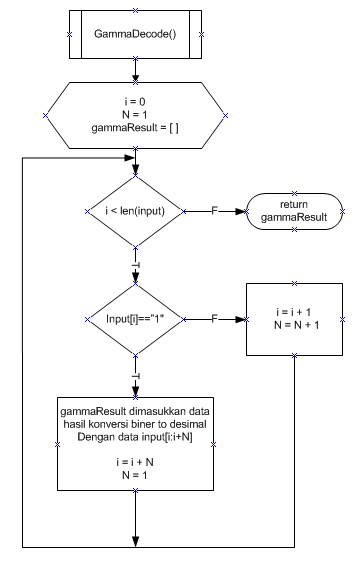



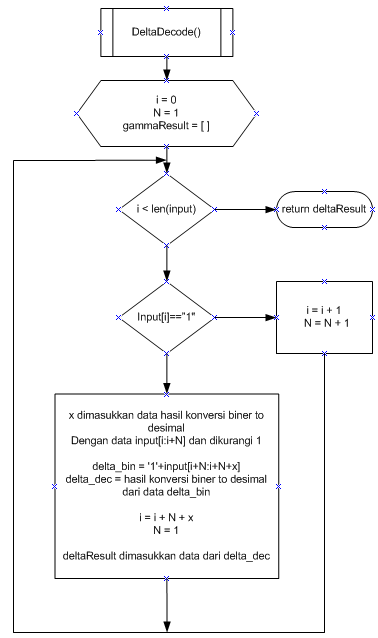



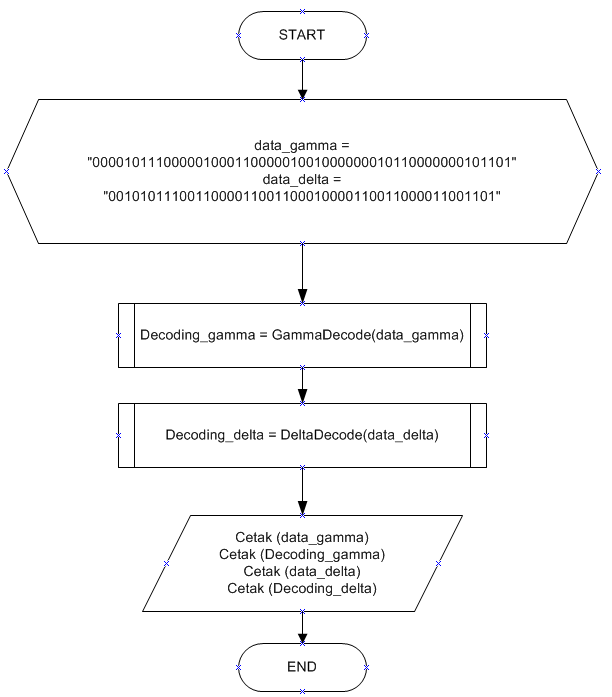



---




© Prof. Hertog Nugroho & Muhammad Yusuf Fadhlan, SST., M.Sc.

Politeknik Negeri Bandung (2023)